# TP1 — MNIST : étude d'un réseau dense (MLP)
**ETRS923 — IA et Objets Connectés · USMB Master ESET** · Auteur : Aris Trache

Objectif : classer les chiffres manuscrits MNIST (28×28 → vecteur de 784 pixels) avec un MLP, et justifier les choix :

1. **Fonction d'activation** (softmax seule, ReLU, tanh, sigmoid) — optimiseur Adam + `categorical_crossentropy`
2. **Optimiseur** (SGD, Adam, RMSprop, Adagrad) sur la meilleure architecture
3. **Fonction coût** (`categorical`, `sparse_categorical`, logits, `binary`)

Pour chaque modèle on mesure : **accuracy test**, **nombre d'epochs** pour converger, **nombre de synapses** (poids + biais, comme `count_neurons_and_synapses` du cours) et **mémoire** nécessaire pour stocker $W$ (float32 vs int8), car c'est ce qui compte pour l'embarquer sur STM32.

> ⚙️ Colab : *Exécution → Modifier le type d'exécution → GPU T4*, puis *Exécution → Tout exécuter*. Durée ≈ 10–15 min.

## 0. Préparation

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Reproductibilité : mêmes poids initiaux et même découpage à chaque exécution
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Paramètres communs à toutes les expériences (identiques => comparaison équitable)
MAX_EPOCHS = 30     # plafond ; l'EarlyStopping arrête avant si ça ne progresse plus
BATCH_SIZE = 128
PATIENCE   = 3      # epochs sans amélioration de val_loss avant arrêt
OUT_DIR    = "resultats_tp1"
os.makedirs(OUT_DIR, exist_ok=True)

print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Données
- Normalisation des pixels de [0, 255] vers [0, 1] : les gradients restent dans une plage raisonnable.
- Aplatissement 28×28 → 784 : un MLP ne voit pas la structure 2D (c'est la limite que les CNN corrigent).
- Deux formats de labels : **entiers** (0–9) pour `sparse_categorical_crossentropy`, **one-hot** pour `categorical_crossentropy`.
- 10 % du jeu d'entraînement sert de **validation** (pour l'early stopping) ; le jeu de **test** n'est utilisé qu'à la fin.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (60000, 784) | Test : (10000, 784)
Exemple de label entier : 5 -> one-hot : [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


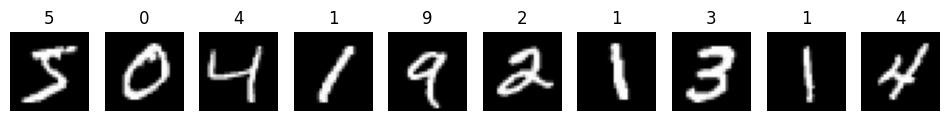

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 784).astype("float32") / 255.0

y_train_oh = tf.keras.utils.to_categorical(y_train, 10)
y_test_oh  = tf.keras.utils.to_categorical(y_test, 10)

print("Train :", x_train.shape, "| Test :", x_test.shape)
print("Exemple de label entier :", y_train[0], "-> one-hot :", y_train_oh[0])

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].reshape(28, 28), cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.show()

## 2. Outils communs
- `build_mlp` construit un MLP : entrée 784 → couches cachées → sortie 10.
- `count_synapses` compte poids + biais et la mémoire associée.
- `run` entraîne, évalue sur le test et renvoie une ligne de résultats.

In [3]:
def build_mlp(hidden=(), activation="relu", out_activation="softmax", n_out=10):
    layers = [tf.keras.Input(shape=(784,))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation=activation))
    layers.append(tf.keras.layers.Dense(n_out, activation=out_activation))
    return tf.keras.Sequential(layers)

def count_synapses(model):
    weights = sum(int(np.prod(l.kernel.shape)) for l in model.layers if hasattr(l, "kernel"))
    total = model.count_params()                     # poids + biais
    neurons = sum(l.units for l in model.layers if hasattr(l, "units"))
    return dict(neurones=neurons, poids=weights, synapses=total,
                **{"mem_float32_ko": round(total * 4 / 1024, 1),
                   "mem_int8_ko":    round(total * 1 / 1024, 1)})

def run(name, model, optimizer="adam", loss="categorical_crossentropy",
        y_tr=None, y_te=None, metrics=("accuracy",)):
    y_tr = y_train_oh if y_tr is None else y_tr
    y_te = y_test_oh  if y_te is None else y_te
    tf.random.set_seed(SEED)
    model.compile(optimizer=optimizer, loss=loss, metrics=list(metrics))
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                          restore_best_weights=True)
    t0 = time.time()
    h = model.fit(x_train, y_tr,
                  validation_split=0.1, epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                  callbacks=[es], verbose=0)
    duree = time.time() - t0
    test_loss, test_acc = model.evaluate(x_test, y_te, verbose=0)
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    row = dict(modele=name, accuracy_test=round(test_acc, 4), loss_test=round(test_loss, 4),
               epochs_meilleur=best_epoch, epochs_total=len(h.history["loss"]),
               temps_s=round(duree, 1), **count_synapses(model))
    print(f"{name:<28} acc={test_acc:.4f}  epochs={best_epoch:>2}  synapses={row['synapses']:>7}  ({duree:.0f}s)")
    return row, h.history, model

def plot_histories(histories, title, key="val_accuracy"):
    plt.figure(figsize=(9, 5))
    for name, hist in histories.items():
        plt.plot(range(1, len(hist[key]) + 1), hist[key], marker="o", ms=3, label=name)
    plt.xlabel("Epoch"); plt.ylabel(key); plt.title(title); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{title.split(' ')[0]}_{key}.png", dpi=150); plt.show()

## 3. Partie 1 — Choix de la fonction d'activation
Optimiseur **Adam**, coût **categorical_crossentropy** fixés (consigne). La sortie est toujours un `softmax` (distribution de probabilité sur 10 classes) ; ce qui change, c'est l'activation des **couches cachées**.

| Question | Architecture |
|---|---|
| a. softmax seule (pas de couche cachée = régression softmax) | 784 → 10 |
| b. ReLU, 2 et 3 couches cachées | 784 → 128 → 64 → 10 · 784 → 256 → 128 → 64 → 10 |
| c. tanh, 1 et 2 couches cachées | 784 → 128 → 10 · 784 → 128 → 64 → 10 |
| d. sigmoid, 1 et 2 couches cachées | 784 → 128 → 10 · 784 → 128 → 64 → 10 |

In [4]:
configs_activation = {
    "a. softmax (784-10)":           dict(hidden=(),             activation=None),
    "b. ReLU 2c (128-64)":           dict(hidden=(128, 64),      activation="relu"),
    "b. ReLU 3c (256-128-64)":       dict(hidden=(256, 128, 64), activation="relu"),
    "c. tanh 1c (128)":              dict(hidden=(128,),         activation="tanh"),
    "c. tanh 2c (128-64)":           dict(hidden=(128, 64),      activation="tanh"),
    "d. sigmoid 1c (128)":           dict(hidden=(128,),         activation="sigmoid"),
    "d. sigmoid 2c (128-64)":        dict(hidden=(128, 64),      activation="sigmoid"),
}
rows, hists, models = [], {}, {}
for name, cfg in configs_activation.items():
    r, h, m = run(name, build_mlp(**cfg))
    rows.append(r); hists[name] = h; models[name] = m

df_act = pd.DataFrame(rows).set_index("modele")
df_act.to_csv(f"{OUT_DIR}/partie1_activations.csv")
df_act

a. softmax (784-10)          acc=0.9279  epochs=22  synapses=   7850  (36s)
b. ReLU 2c (128-64)          acc=0.9719  epochs= 7  synapses= 109386  (19s)
b. ReLU 3c (256-128-64)      acc=0.9724  epochs= 3  synapses= 242762  (13s)
c. tanh 1c (128)             acc=0.9768  epochs=14  synapses= 101770  (26s)
c. tanh 2c (128-64)          acc=0.9761  epochs=17  synapses= 109386  (30s)
d. sigmoid 1c (128)          acc=0.9786  epochs=26  synapses= 101770  (40s)
d. sigmoid 2c (128-64)       acc=0.9754  epochs=16  synapses= 109386  (29s)


,accuracy_test,loss_test,epochs_meilleur,epochs_total,temps_s,neurones,poids,synapses,mem_float32_ko,mem_int8_ko
modele,,,,,,,,,,
a. softmax (784-10),0.9279,0.2617,22,25,35.5,10,7840,7850,30.7,7.7
b. ReLU 2c (128-64),0.9719,0.0860,7,10,19.4,202,109184,109386,427.3,106.8
b. ReLU 3c (256-128-64),0.9724,0.0869,3,6,12.5,458,242304,242762,948.3,237.1
c. tanh 1c (128),0.9768,0.0753,14,17,25.7,138,101632,101770,397.5,99.4
c. tanh 2c (128-64),0.9761,0.0962,17,20,29.8,202,109184,109386,427.3,106.8
d. sigmoid 1c (128),0.9786,0.0710,26,29,40.3,138,101632,101770,397.5,99.4
d. sigmoid 2c (128-64),0.9754,0.0790,16,19,28.7,202,109184,109386,427.3,106.8


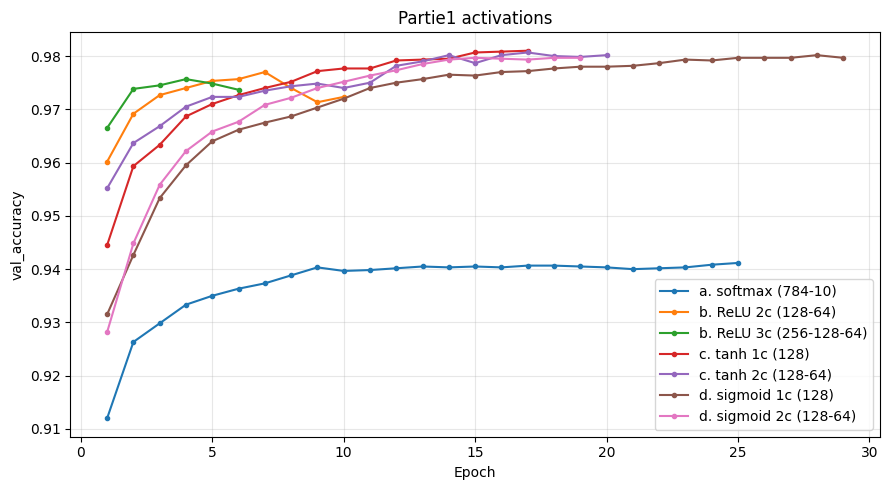

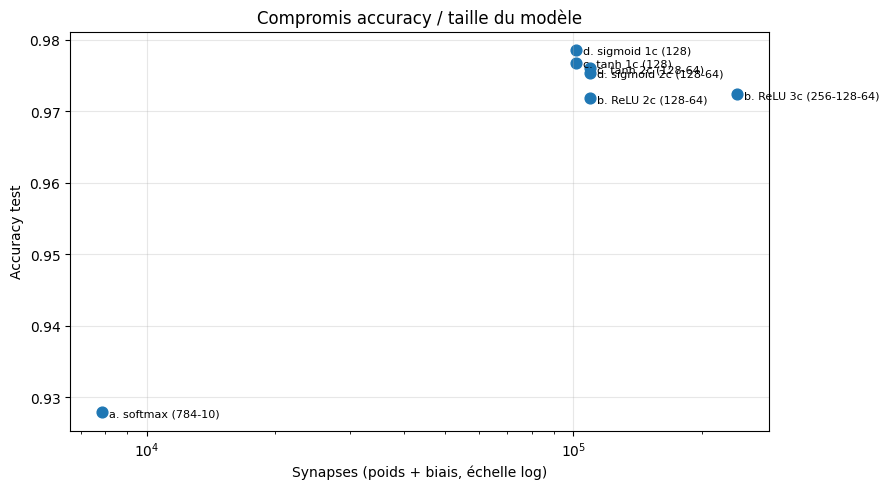

In [5]:
plot_histories(hists, "Partie1 activations")

# Compromis accuracy / taille : le graphe clé pour justifier le choix
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df_act["synapses"], df_act["accuracy_test"], s=60)
for name, r in df_act.iterrows():
    ax.annotate(name, (r["synapses"], r["accuracy_test"]), fontsize=8, xytext=(5, -3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Synapses (poids + biais, échelle log)"); ax.set_ylabel("Accuracy test")
ax.set_title("Compromis accuracy / taille du modèle"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/partie1_compromis.png", dpi=150); plt.show()

### e. Choix de l'architecture
Critère retenu (à défendre à l'oral) : **la meilleure accuracy par Ko de mémoire**, en écartant les modèles trop faibles. On ne prend pas forcément le plus précis : sur un microcontrôleur (Flash 512 Ko, RAM 320 Ko sur la N657), un modèle 2× plus gros pour +0,2 % d'accuracy est un mauvais compromis.

La cellule ci-dessous propose automatiquement : *le plus petit modèle dont l'accuracy est à moins de 0,5 point du meilleur*. Tu peux forcer ton choix en remplaçant `BEST`.

In [6]:
TOL = 0.005
seuil = df_act["accuracy_test"].max() - TOL
candidats = df_act[df_act["accuracy_test"] >= seuil].sort_values("synapses")
BEST = candidats.index[0]          # <- remplace par un nom de la table pour forcer ton choix
best_cfg = configs_activation[BEST]
print(f"Architecture retenue : {BEST}")
print(df_act.loc[BEST, ["accuracy_test", "epochs_meilleur", "synapses", "mem_float32_ko", "mem_int8_ko"]])

Architecture retenue : c. tanh 1c (128)
accuracy_test           0.9768
epochs_meilleur        14.0000
synapses           101770.0000
mem_float32_ko        397.5000
mem_int8_ko            99.4000
Name: c. tanh 1c (128), dtype: float64


## 4. Partie 2 — Choix de l'optimiseur
Même architecture (`BEST`), même coût, taux d'apprentissage **par défaut de Keras** pour chaque optimiseur (SGD 0.01, Adam 0.001, RMSprop 0.001, Adagrad 0.001). On compare vitesse de convergence et accuracy finale.

SGD                          acc=0.9359  epochs=30  synapses= 101770  (39s)
Adam                         acc=0.9759  epochs=13  synapses= 101770  (24s)
RMSprop                      acc=0.9774  epochs=16  synapses= 101770  (26s)
Adagrad                      acc=0.9088  epochs=30  synapses= 101770  (41s)


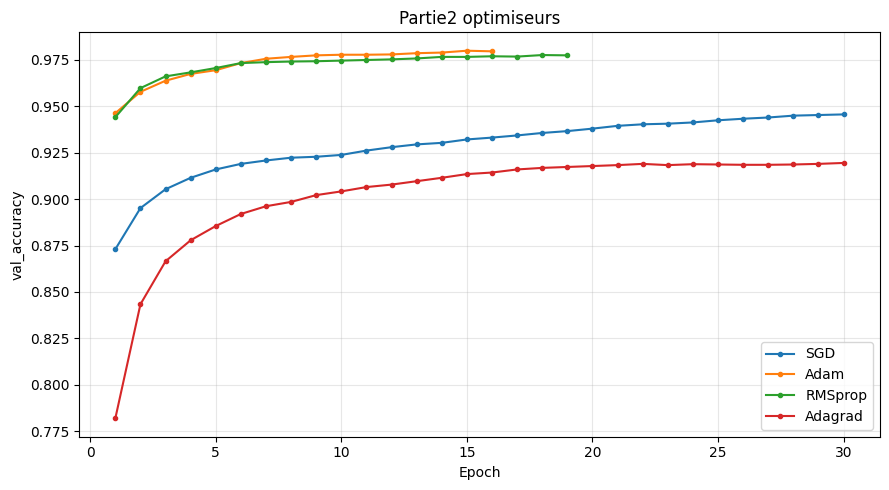

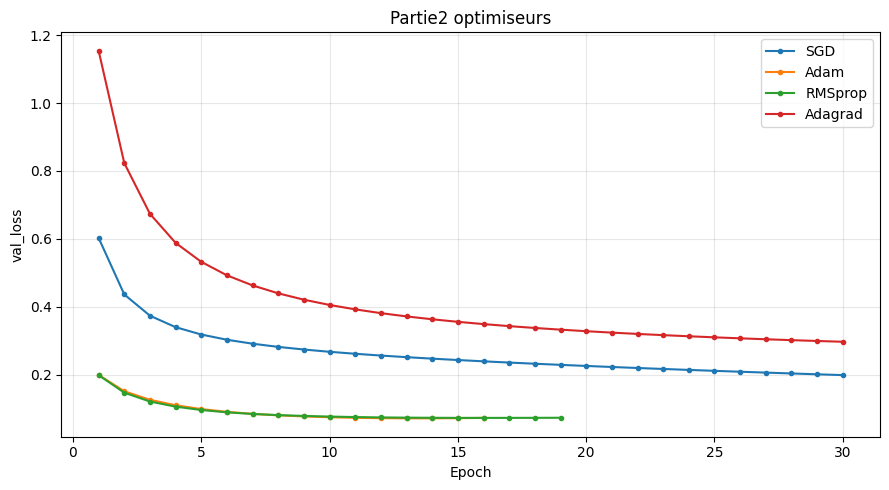

,accuracy_test,loss_test,epochs_meilleur,epochs_total,temps_s
modele,,,,,
SGD,0.9359,0.2298,30,30,39.4
Adam,0.9759,0.0769,13,16,24.4
RMSprop,0.9774,0.0756,16,19,26.3
Adagrad,0.9088,0.3380,30,30,41.0


In [7]:
optimizers = {
    "SGD":     lambda: tf.keras.optimizers.SGD(),
    "Adam":    lambda: tf.keras.optimizers.Adam(),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(),
    "Adagrad": lambda: tf.keras.optimizers.Adagrad(),
}
rows, hists_opt = [], {}
for name, make_opt in optimizers.items():
    r, h, _ = run(name, build_mlp(**best_cfg), optimizer=make_opt())
    rows.append(r); hists_opt[name] = h

df_opt = pd.DataFrame(rows).set_index("modele")
df_opt.to_csv(f"{OUT_DIR}/partie2_optimiseurs.csv")
plot_histories(hists_opt, "Partie2 optimiseurs")
plot_histories(hists_opt, "Partie2 optimiseurs", key="val_loss")
df_opt[["accuracy_test", "loss_test", "epochs_meilleur", "epochs_total", "temps_s"]]

**À observer** : SGD et Adagrad convergent lentement (pas fixe trop petit / taux qui décroît sans cesse) et n'atteignent souvent pas leur optimum en 30 epochs ; Adam et RMSprop adaptent le pas par paramètre et convergent en quelques epochs. Le choix de l'optimiseur n'a **aucun impact sur la taille du modèle embarqué** : il ne joue que sur le coût d'entraînement (temps, énergie côté PC/Cloud).

## 5. Partie 3 — Choix de la fonction coût
Le coût doit être cohérent avec **la sortie du modèle** et **l'encodage des labels** :

| Variante | Sortie | Labels | Coût |
|---|---|---|---|
| Multi-classe one-hot | softmax (10) | `[0,0,1,…]` | `categorical_crossentropy` |
| Multi-classe entiers | softmax (10) | `0…9` | `sparse_categorical_crossentropy` |
| Multi-classe logits | linéaire (10) | `0…9` | `SparseCategoricalCrossentropy(from_logits=True)` |
| Binaire (adapté : **chiffre pair / impair**) | sigmoid (1) | `0/1` | `binary_crossentropy` |

Pour le binaire on reformule le problème, car MNIST est multi-classe par nature.

In [8]:
y_train_bin = (y_train % 2 == 1).astype("float32")   # 1 = impair
y_test_bin  = (y_test  % 2 == 1).astype("float32")
H, A = best_cfg["hidden"], best_cfg["activation"]

rows = []
r, _, _ = run("categorical (one-hot)", build_mlp(H, A, "softmax"),
              loss="categorical_crossentropy"); rows.append(r)
r, _, _ = run("sparse_categorical (entiers)", build_mlp(H, A, "softmax"),
              loss="sparse_categorical_crossentropy", y_tr=y_train, y_te=y_test); rows.append(r)
r, _, m_logits = run("sparse + logits", build_mlp(H, A, None),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              y_tr=y_train, y_te=y_test); rows.append(r)
r, _, _ = run("binary (pair/impair)", build_mlp(H, A, "sigmoid", n_out=1),
              loss="binary_crossentropy", y_tr=y_train_bin, y_te=y_test_bin); rows.append(r)

df_loss = pd.DataFrame(rows).set_index("modele")
df_loss.to_csv(f"{OUT_DIR}/partie3_couts.csv")
df_loss[["accuracy_test", "loss_test", "epochs_meilleur", "synapses"]]

categorical (one-hot)        acc=0.9766  epochs=13  synapses= 101770  (24s)
sparse_categorical (entiers) acc=0.9748  epochs=14  synapses= 101770  (26s)
sparse + logits              acc=0.9742  epochs=16  synapses= 101770  (28s)
binary (pair/impair)         acc=0.9857  epochs=10  synapses= 100609  (20s)


,accuracy_test,loss_test,epochs_meilleur,synapses
modele,,,,
categorical (one-hot),0.9766,0.0772,13,101770
sparse_categorical (entiers),0.9748,0.0798,14,101770
sparse + logits,0.9742,0.0844,16,101770
binary (pair/impair),0.9857,0.0413,10,100609


**À observer** : les trois variantes multi-classes donnent la même accuracy (c'est mathématiquement le même problème, seul le format change). `sparse` évite de stocker les labels en one-hot (10× moins de mémoire pour les labels). La version **logits** est numériquement plus stable et, en embarqué, permet de **supprimer le softmax** à l'inférence : `argmax(logits) == argmax(softmax(logits))`, donc on économise un calcul d'exponentielles sur le MCU. Le binaire n'est pas comparable (problème différent, 2 classes).

In [9]:
# Preuve : argmax des logits == argmax du softmax -> le softmax est inutile pour décider de la classe
logits = m_logits.predict(x_test[:1000], verbose=0)
print("Décisions identiques :", np.array_equal(np.argmax(logits, 1), np.argmax(tf.nn.softmax(logits), 1)))

Décisions identiques : True


## 6. Sauvegarde du modèle retenu et des résultats

In [10]:
final_model = build_mlp(**best_cfg)
r, h, final_model = run(f"FINAL {BEST} + Adam", final_model)
fname = f"{OUT_DIR}/mnist_mlp_acc{r['accuracy_test']:.4f}.keras"
final_model.save(fname)
print("Modèle sauvegardé :", fname)

with pd.ExcelWriter(f"{OUT_DIR}/synthese_tp1.xlsx") as w:
    df_act.to_excel(w, sheet_name="activations"); df_opt.to_excel(w, sheet_name="optimiseurs"); df_loss.to_excel(w, sheet_name="couts")

try:                       # téléchargement automatique sous Colab
    import shutil
    from google.colab import files
    shutil.make_archive("resultats_tp1", "zip", OUT_DIR)
    files.download("resultats_tp1.zip")
except ImportError:
    print("Hors Colab : résultats dans le dossier", OUT_DIR)

FINAL c. tanh 1c (128) + Adam acc=0.9781  epochs=15  synapses= 101770  (26s)
Modèle sauvegardé : resultats_tp1/mnist_mlp_acc0.9781.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Conclusion (à compléter avec TES chiffres)
- **Activation** : … (ex. ReLU converge plus vite que sigmoid/tanh car pas de saturation du gradient ; la softmax seule plafonne vers ~92 % car le modèle est linéaire.)
- **Architecture retenue** : … synapses, … Ko en float32 / … Ko en int8, … % d'accuracy.
- **Optimiseur** : … (Adam : convergence en … epochs contre … pour SGD.)
- **Coût** : sparse + logits recommandé pour l'embarqué (pas de one-hot, pas de softmax à l'inférence).
- **Lien embarqué** : la quantification int8 divise la mémoire par 4 — c'est ce qui permettra le déploiement X-CUBE-AI au TP3.